In [1]:
import os
import numpy as np
import pyccl as ccl
import healpy as hp
import matplotlib.pyplot as plt
import libconf
from astropy.io import fits

import camb
from camb import model, initialpower
import treecorr
import fitsio
import time
import pprint
import pandas as pd
import camb
from camb import model
from camb.sources import SplinedSourceWindow

import pymaster as nmt
from miscelanious import cosmology, get_pk, dndz_des_alonso, _gen_random_catalogue_theta, W_err
from make_functions import make_treecorr_maps, make_camb, make_w_theta

In [2]:
galaxy_full_maps = sorted([f for f in os.listdir('./high_res_colore/')  if f.startswith('full_sky') and os.path.isfile(os.path.join('./high_res_colore/', f))])
H1_maps = sorted([f for f in os.listdir('./high_res_colore/')  if f.startswith('hi_gal_run_imap_s1') and os.path.isfile(os.path.join('./high_res_colore/', f))])
print(galaxy_full_maps)

['full_sky_gal_z_0.40_0.46.csv', 'full_sky_gal_z_0.46_0.53.csv', 'full_sky_gal_z_0.53_0.61.csv', 'full_sky_gal_z_0.61_0.69.csv', 'full_sky_gal_z_0.69_0.78.csv', 'full_sky_gal_z_0.78_0.88.csv', 'full_sky_gal_z_0.88_1.00.csv', 'full_sky_gal_z_1.00_1.13.csv', 'full_sky_gal_z_1.13_1.28.csv', 'full_sky_gal_z_1.28_1.45.csv']


Processing full_sky_gal_z_0.40_0.46.csv
Finished pixelization on full_sky_gal_z_0.40_0.46.csv
full_sky_gal_z_0.40_0.46.csv Delta map saved
full_sky_gal_z_0.40_0.46.csv C_ell saved


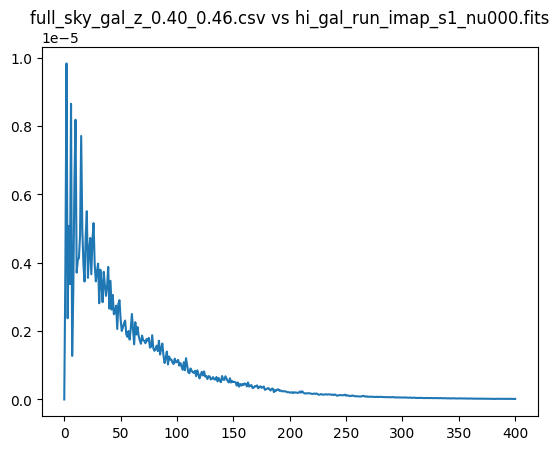

Processing full_sky_gal_z_0.46_0.53.csv
Finished pixelization on full_sky_gal_z_0.46_0.53.csv
full_sky_gal_z_0.46_0.53.csv Delta map saved
full_sky_gal_z_0.46_0.53.csv C_ell saved


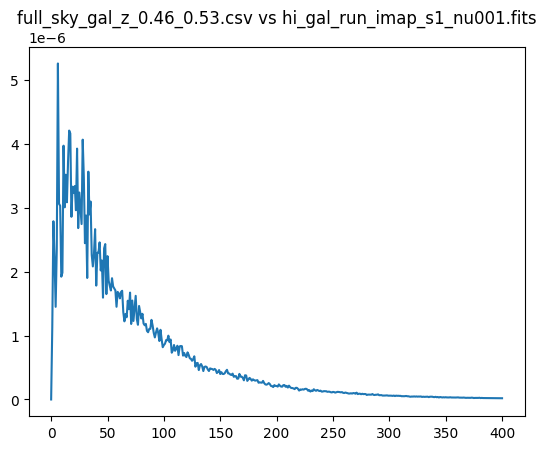

Processing full_sky_gal_z_0.53_0.61.csv
Finished pixelization on full_sky_gal_z_0.53_0.61.csv
full_sky_gal_z_0.53_0.61.csv Delta map saved
full_sky_gal_z_0.53_0.61.csv C_ell saved


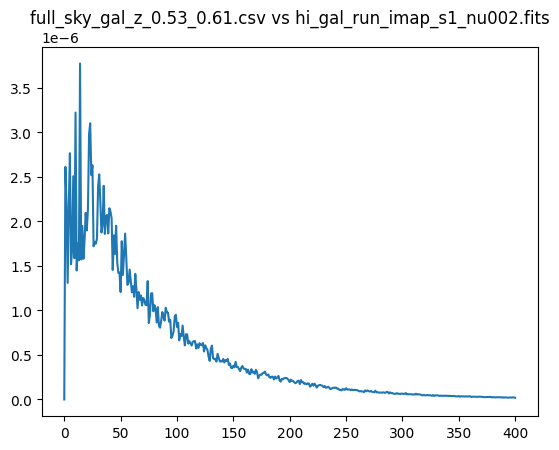

Processing full_sky_gal_z_0.61_0.69.csv
Finished pixelization on full_sky_gal_z_0.61_0.69.csv
full_sky_gal_z_0.61_0.69.csv Delta map saved
full_sky_gal_z_0.61_0.69.csv C_ell saved


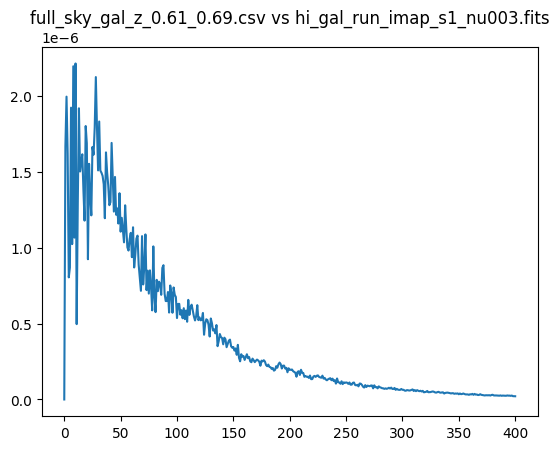

Processing full_sky_gal_z_0.69_0.78.csv
Finished pixelization on full_sky_gal_z_0.69_0.78.csv
full_sky_gal_z_0.69_0.78.csv Delta map saved
full_sky_gal_z_0.69_0.78.csv C_ell saved


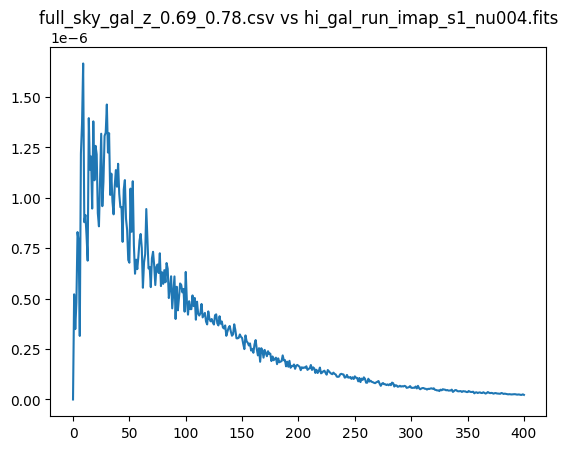

Processing full_sky_gal_z_0.78_0.88.csv
Finished pixelization on full_sky_gal_z_0.78_0.88.csv
full_sky_gal_z_0.78_0.88.csv Delta map saved
full_sky_gal_z_0.78_0.88.csv C_ell saved


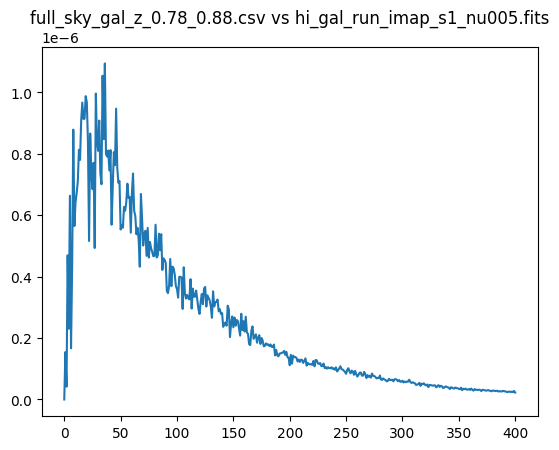

Processing full_sky_gal_z_0.88_1.00.csv
Finished pixelization on full_sky_gal_z_0.88_1.00.csv
full_sky_gal_z_0.88_1.00.csv Delta map saved
full_sky_gal_z_0.88_1.00.csv C_ell saved


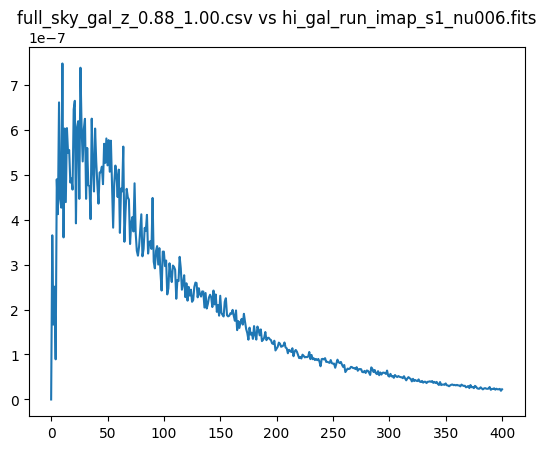

Processing full_sky_gal_z_1.00_1.13.csv
Finished pixelization on full_sky_gal_z_1.00_1.13.csv
full_sky_gal_z_1.00_1.13.csv Delta map saved
full_sky_gal_z_1.00_1.13.csv C_ell saved


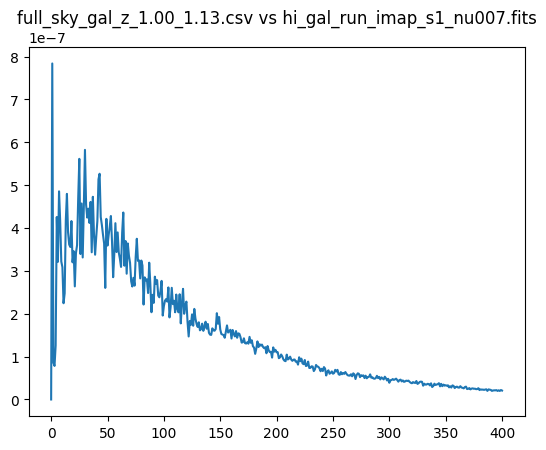

Processing full_sky_gal_z_1.13_1.28.csv
Finished pixelization on full_sky_gal_z_1.13_1.28.csv
full_sky_gal_z_1.13_1.28.csv Delta map saved
full_sky_gal_z_1.13_1.28.csv C_ell saved


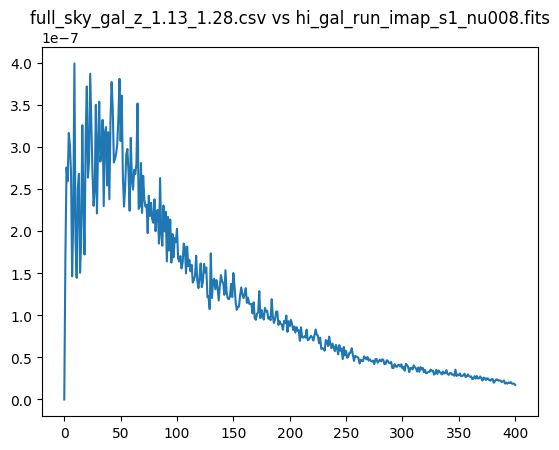

Processing full_sky_gal_z_1.28_1.45.csv
Finished pixelization on full_sky_gal_z_1.28_1.45.csv
full_sky_gal_z_1.28_1.45.csv Delta map saved
full_sky_gal_z_1.28_1.45.csv C_ell saved


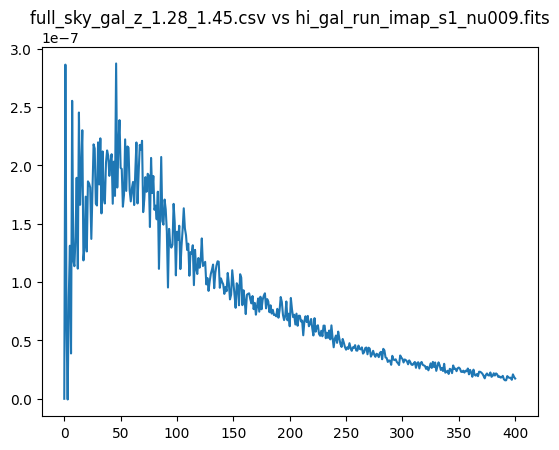

In [13]:
nside = 1024
npix = hp.nside2npix(nside)
chunksize = 2_000_000

for i, map_file in enumerate(galaxy_full_maps):

    print(f"Processing {map_file}")

    ncount = np.zeros(npix, dtype=np.float64)
    janela_list = []

    for chunk in pd.read_csv(f"./high_res_colore/{map_file}", chunksize=chunksize):

        ra  = chunk["RA"].values
        dec = chunk["DEC"].values
        ipix = hp.ang2pix(nside, ra, dec, lonlat=True)
        binc = np.bincount(ipix, minlength=npix)
        ncount += binc

        # mask = ((ra >= 80) & (ra <= 110) &
                # (dec >= -10) & (dec <= 10))
        # if np.any(mask):
        #     janela_list.append(chunk.loc[mask])

        del chunk, ra, dec, ipix, binc#, mask

    print(f"Finished pixelization on {map_file}")

    # --- Compute delta map ---
    mean = np.mean(ncount)
    delta_map = (ncount - mean) / mean
    # hp.write_map(f"./high_res_colore/delta_g_{map_file[:-4]}.fits", delta_map, overwrite=True)
    print(f"{map_file} Delta map saved")

    # --- Compute Delta T map ---
    t_map = hp.read_map(f'./high_res_colore/{H1_maps[i]}')
    t_mean = np.mean(t_map)
    Delta_T = t_map - t_mean

    # --- Compute C_ell ---
    cl_cross = hp.anafast(delta_map, Delta_T, lmax=400)
    # np.save(f"./high_res_colore/cl_gal_{map_file[:-4]}.npy", cl_gal)
    print(f"{map_file} C_ell saved")
    plt.plot(cl_cross)
    plt.title(f'{map_file} vs {H1_maps[i]}')
    plt.show()

    # --- Save window data ---
    # if len(janela_list) > 0:
    #     janela = pd.concat(janela_list, ignore_index=True)
    #     janela.to_parquet(f"./high_res_colore/janela_{map_file[:-4]}.parquet")
    #     print("Window saved:", len(janela))
    # else:
    #     print("No objects in window")

    # Free memory
    del ncount, delta_map, cl_cross#, janela_list


Processing full_sky_gal_z_0.40_0.46.csv
Finished pixelization on full_sky_gal_z_0.40_0.46.csv
full_sky_gal_z_0.40_0.46.csv Delta map saved
full_sky_gal_z_0.40_0.46.csv C_ell saved


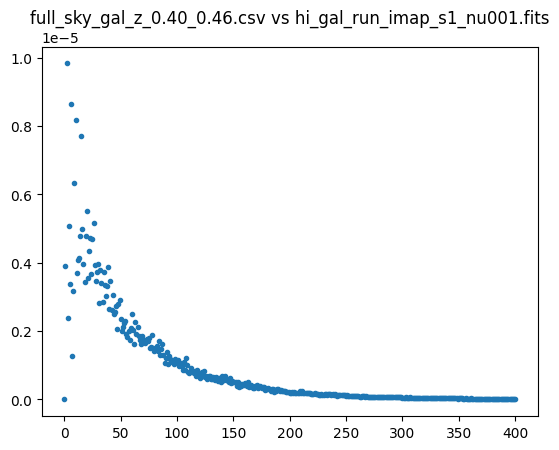

Processing full_sky_gal_z_0.46_0.53.csv
Finished pixelization on full_sky_gal_z_0.46_0.53.csv
full_sky_gal_z_0.46_0.53.csv Delta map saved
full_sky_gal_z_0.46_0.53.csv C_ell saved


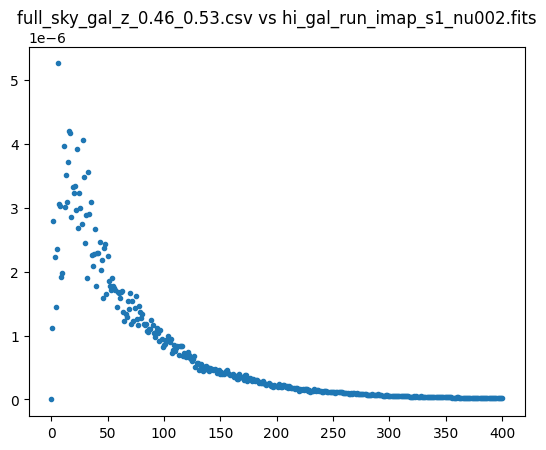

Processing full_sky_gal_z_0.53_0.61.csv
Finished pixelization on full_sky_gal_z_0.53_0.61.csv
full_sky_gal_z_0.53_0.61.csv Delta map saved
full_sky_gal_z_0.53_0.61.csv C_ell saved


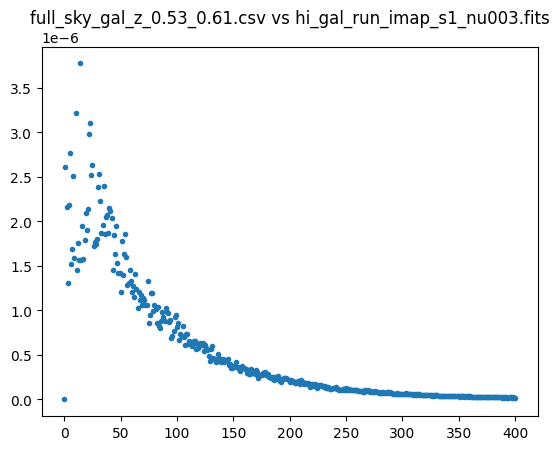

Processing full_sky_gal_z_0.61_0.69.csv
Finished pixelization on full_sky_gal_z_0.61_0.69.csv
full_sky_gal_z_0.61_0.69.csv Delta map saved
full_sky_gal_z_0.61_0.69.csv C_ell saved


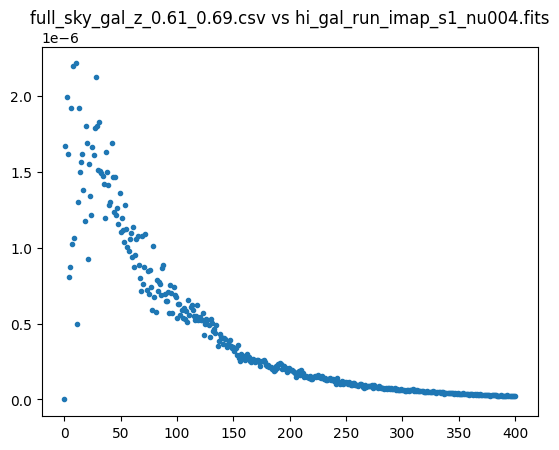

Processing full_sky_gal_z_0.69_0.78.csv
Finished pixelization on full_sky_gal_z_0.69_0.78.csv
full_sky_gal_z_0.69_0.78.csv Delta map saved
full_sky_gal_z_0.69_0.78.csv C_ell saved


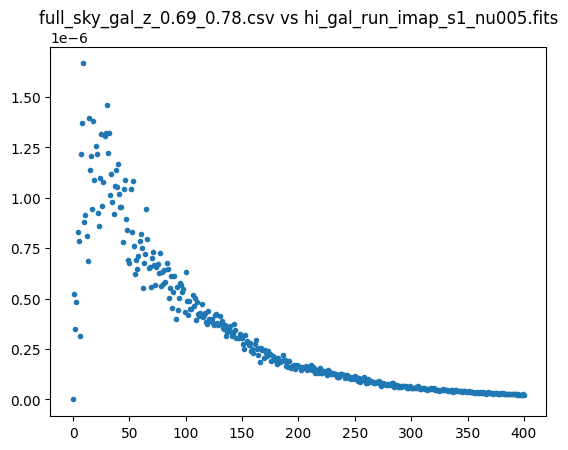

Processing full_sky_gal_z_0.78_0.88.csv
Finished pixelization on full_sky_gal_z_0.78_0.88.csv
full_sky_gal_z_0.78_0.88.csv Delta map saved
full_sky_gal_z_0.78_0.88.csv C_ell saved


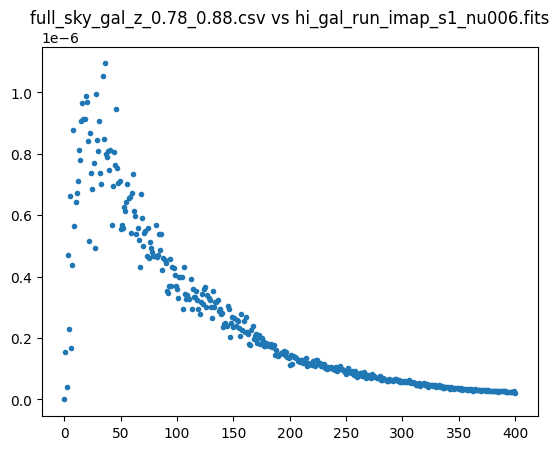

Processing full_sky_gal_z_0.88_1.00.csv
Finished pixelization on full_sky_gal_z_0.88_1.00.csv
full_sky_gal_z_0.88_1.00.csv Delta map saved
full_sky_gal_z_0.88_1.00.csv C_ell saved


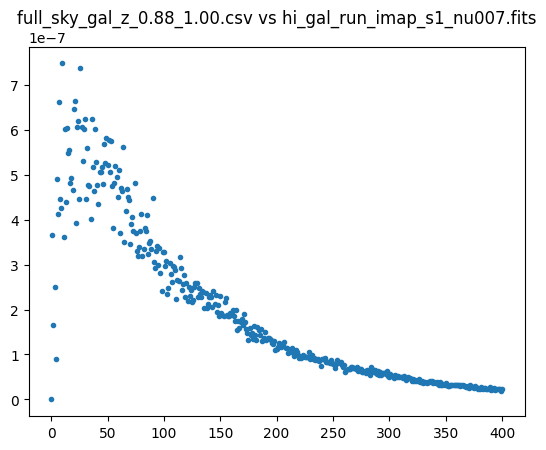

Processing full_sky_gal_z_1.00_1.13.csv
Finished pixelization on full_sky_gal_z_1.00_1.13.csv
full_sky_gal_z_1.00_1.13.csv Delta map saved
full_sky_gal_z_1.00_1.13.csv C_ell saved


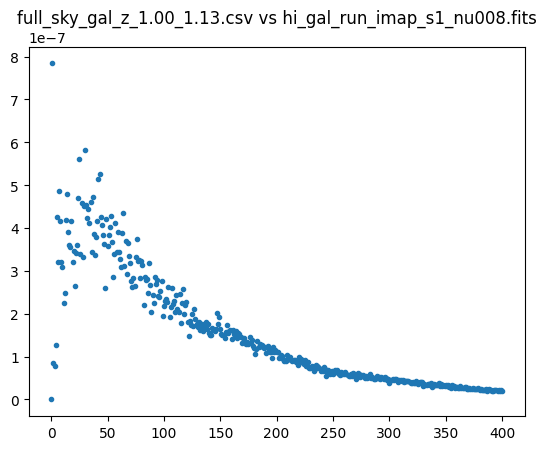

Processing full_sky_gal_z_1.13_1.28.csv
Finished pixelization on full_sky_gal_z_1.13_1.28.csv
full_sky_gal_z_1.13_1.28.csv Delta map saved
full_sky_gal_z_1.13_1.28.csv C_ell saved


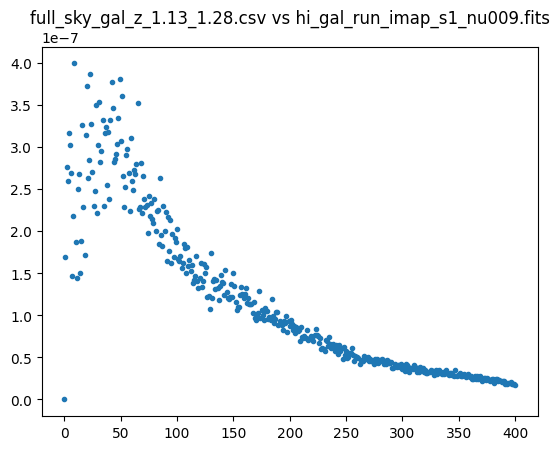

Processing full_sky_gal_z_1.28_1.45.csv
Finished pixelization on full_sky_gal_z_1.28_1.45.csv
full_sky_gal_z_1.28_1.45.csv Delta map saved
full_sky_gal_z_1.28_1.45.csv C_ell saved


IndexError: list index out of range

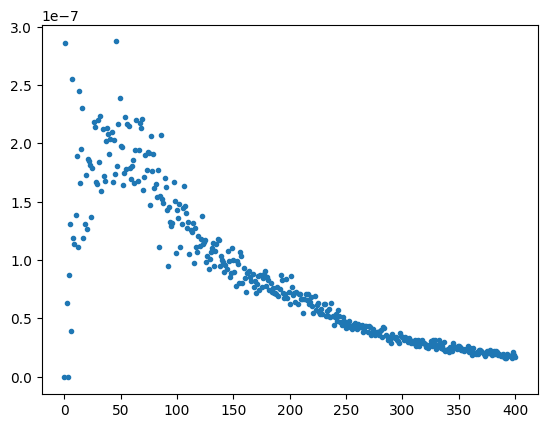

In [3]:
nside = 1024
npix = hp.nside2npix(nside)
chunksize = 2_000_000

for i, map_file in enumerate(galaxy_full_maps):

    print(f"Processing {map_file}")

    ncount = np.zeros(npix, dtype=np.float64)
    janela_list = []

    for chunk in pd.read_csv(f"./high_res_colore/{map_file}", chunksize=chunksize):

        ra  = chunk["RA"].values
        dec = chunk["DEC"].values
        ipix = hp.ang2pix(nside, ra, dec, lonlat=True)
        binc = np.bincount(ipix, minlength=npix)
        ncount += binc

        # mask = ((ra >= 80) & (ra <= 110) &
                # (dec >= -10) & (dec <= 10))
        # if np.any(mask):
        #     janela_list.append(chunk.loc[mask])

        del chunk, ra, dec, ipix, binc#, mask

    print(f"Finished pixelization on {map_file}")

    # --- Compute delta map ---
    mean = np.mean(ncount)
    delta_map = (ncount - mean) / mean
    # hp.write_map(f"./high_res_colore/delta_g_{map_file[:-4]}.fits", delta_map, overwrite=True)
    print(f"{map_file} Delta map saved")

    # --- Compute Delta T map ---
    t_map = hp.read_map(f'./high_res_colore/{H1_maps[i]}')
    t_mean = np.mean(t_map)
    Delta_T = t_map - t_mean

    # --- Compute C_ell ---
    cl_cross = hp.anafast(delta_map, Delta_T, lmax=400)
    # np.save(f"./high_res_colore/cl_gal_{map_file[:-4]}.npy", cl_gal)
    print(f"{map_file} C_ell saved")
    plt.plot(cl_cross, '.')
    plt.title(f'{map_file} vs {H1_maps[i]}')
    plt.show()

    # --- Save window data ---
    # if len(janela_list) > 0:
    #     janela = pd.concat(janela_list, ignore_index=True)
    #     janela.to_parquet(f"./high_res_colore/janela_{map_file[:-4]}.parquet")
    #     print("Window saved:", len(janela))
    # else:
    #     print("No objects in window")

    # Free memory
    del ncount, delta_map, cl_cross#, janela_list


In [ ]:
# for map_file in H1_maps:

#     print(f"Processing {map_file}")

#     map_data = hp.read_map(f'./high_res_colore/{map_file}')
#     nside = hp.get_nside(map_data)
#     npix = hp.get_map_size(map_data)
#     idx = np.arange(npix)
#     theta, phi = hp.pix2ang(nside, idx)
#     ra = np.degrees(phi)
#     dec = 90.0-np.degrees(theta)

#     mask = ((ra >= 80) & (ra <= 110) & (dec >= -10) & (dec <= 10))
#     janela_list = map_data[mask]

#     print(f"Finished pixelization on {map_file}")

#     # --- Compute delta map ---
#     mean = np.mean(map_data)
#     Delta_map = (map_data - mean)
#     hp.write_map(f"./high_res_colore/Delta_T_{map_file[:-5]}.fits", Delta_map, overwrite=True)
#     print(f"{map_file} Delta map saved")

#     # --- Compute C_ell ---
#     cl_H1 = hp.anafast(Delta_map, lmax=400)
#     np.save(f"./high_res_colore/cl_H1_{map_file[:-5]}.npy", cl_H1)
#     print(f"{map_file} C_ell saved")

#     # --- Save window data ---
#     if len(janela_list) > 0:
#         window_map = np.full(npix, hp.UNSEEN)
#         window_map[mask] = map_data[mask]
#         hp.write_map(f"./high_res_colore/window_H1_{map_file[:-5]}.fits", window_map, overwrite=True)
#         print("Window saved:", len(janela_list))
#     else:
#         print("No objects in window")

#     # Free memory
#     del map_data, nside, npix, idx, theta, phi, ra, dec, janela_list, mean, Delta_map, cl_H1

Processing hi_gal_run_imap_s1_nu008.fits


setting the output map dtype to [dtype('float32')]


Finished pixelization on hi_gal_run_imap_s1_nu008.fits
hi_gal_run_imap_s1_nu008.fits Delta map saved


setting the output map dtype to [dtype('float64')]


hi_gal_run_imap_s1_nu008.fits C_ell saved
Window saved: 45523
Processing hi_gal_run_imap_s1_nu007.fits


setting the output map dtype to [dtype('float32')]


... (31 outputs left out)

setting the output map dtype to [dtype('float32')]


Finished pixelization on hi_gal_run_imap_s1_nu006.fits
hi_gal_run_imap_s1_nu006.fits Delta map saved


setting the output map dtype to [dtype('float64')]


hi_gal_run_imap_s1_nu006.fits C_ell saved
Window saved: 45523


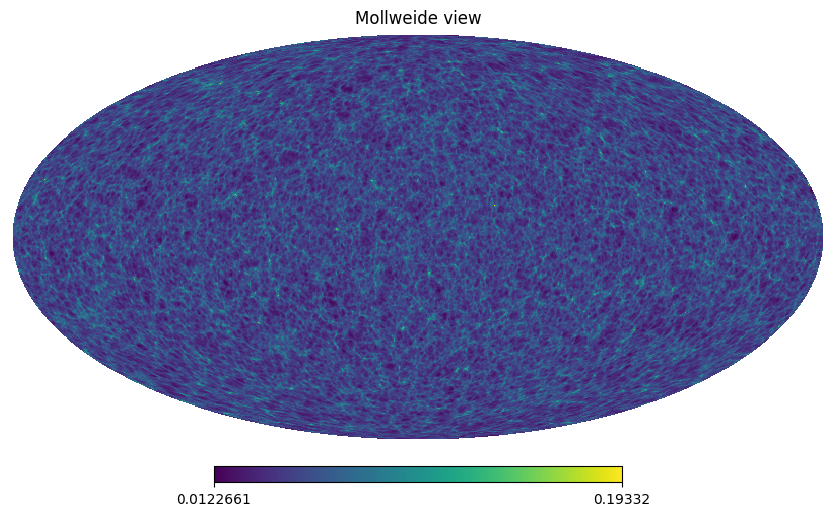

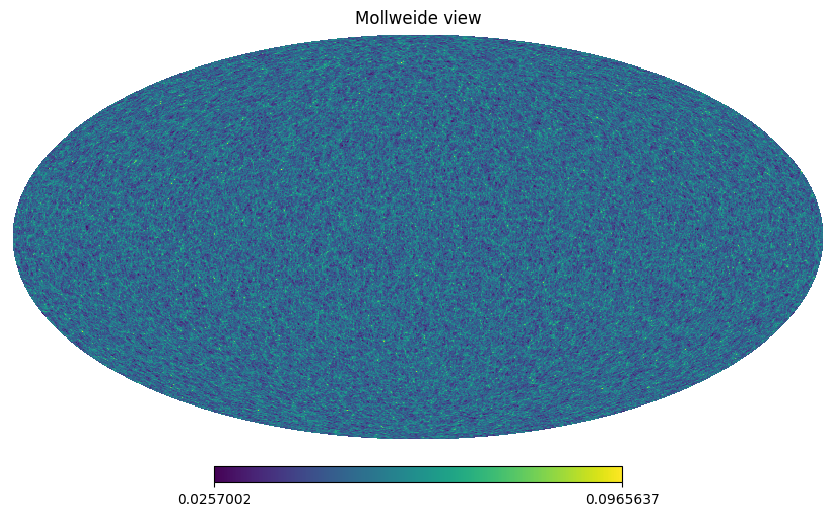

In [4]:
hp.mollview(hp.read_map('./high_res_colore/hi_gal_run_imap_s1_nu000.fits'))
hp.mollview(hp.read_map('./high_res_colore/hi_gal_run_imap_s1_nu009.fits'))

redshift interval 1.45 - 1.28 done
redshift interval 1.28 - 1.13 done
redshift interval 1.13 - 1.0 done
redshift interval 1.0 - 0.88 done
redshift interval 0.88 - 0.78 done
redshift interval 0.78 - 0.69 done
redshift interval 0.69 - 0.61 done
redshift interval 0.61 - 0.53 done
redshift interval 0.53 - 0.46 done
redshift interval 0.46 - 0.4 done


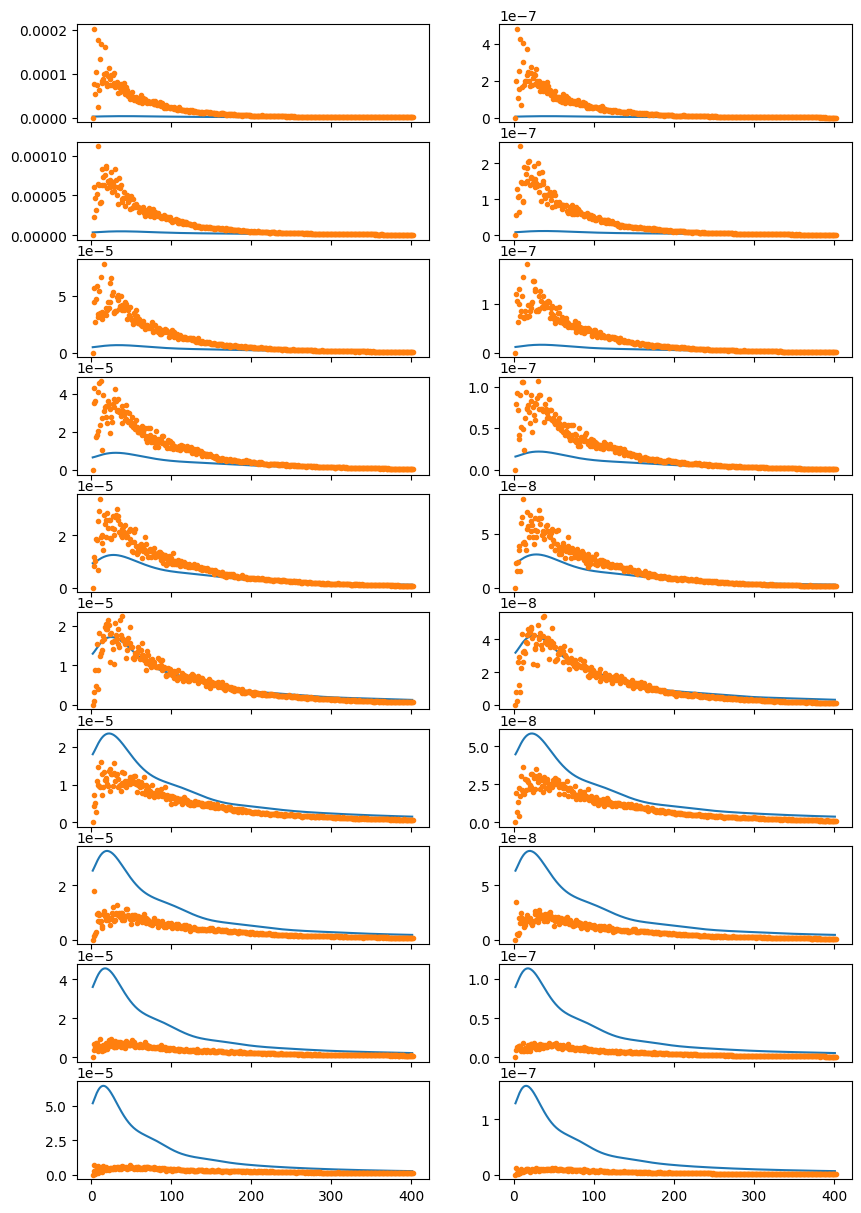

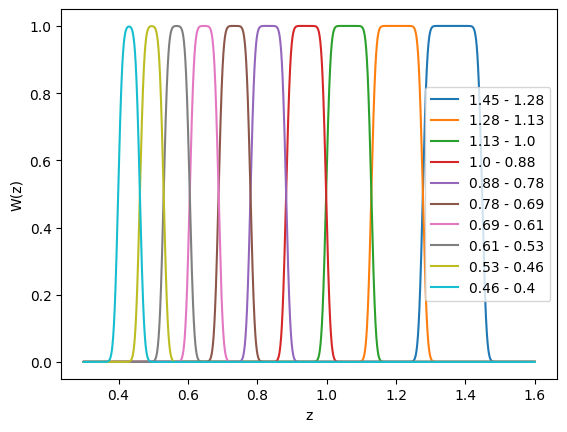

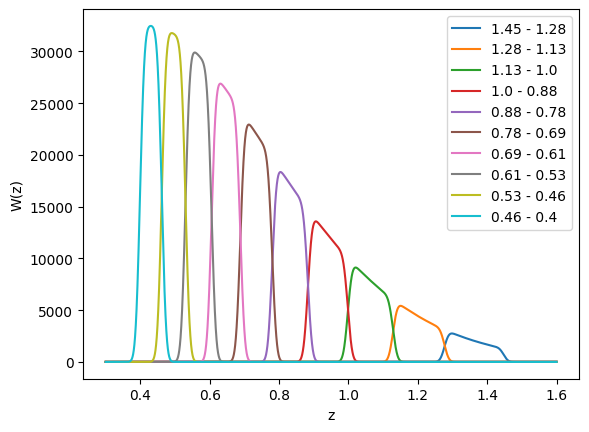

In [ ]:
nu_table = np.loadtxt('./high_res_colore/nuTable.txt')
redshift_limit = (1420.0 / nu_table) - 1

redshift = np.linspace(0.3, 1.6, 100000)
dndz = dndz_des_alonso(redshift)
bias = np.ones_like(redshift)

csm = cosmology(0.31, 0.05, 1-0.31, 0.6774, -1.0, 0.967, np.nan, 2.142e-9)
csm, kh, pkh, f = get_pk(csm, 0.0)

gal_cls_files = [sorted([f for f in os.listdir('./high_res_colore/')  if f.startswith('cl_gal') and os.path.isfile(os.path.join('./high_res_colore/', f))])]
H1_cls_files = [sorted([f for f in os.listdir('./high_res_colore/')  if f.startswith('cl_H1') and os.path.isfile(os.path.join('./high_res_colore/', f))])]

check_ws, check_w_gal = [], []

fig, ax = plt.subplots(10,2, figsize = (10, 15), sharex=True)
for i in range(10):
    # print(gal_cls_files[0][i])
    Ws = W_err(redshift, (redshift_limit[i][1] + redshift_limit[i][0])/2, abs(redshift_limit[i][1] - redshift_limit[i][0])/2, 0.005)
    
    check_ws.append(Ws)

    W_gal = dndz * Ws

    check_w_gal.append(W_gal)

    theory_ell_gal, theory_Cell_gal = make_camb(csm, 5000, redshift, W_gal, bias, cross = False)
    theory_ell_H1, theory_Cell_H1 = make_camb(csm, 5000, redshift, Ws, bias, cross = False)

    sim_Cell_gal = np.load('./high_res_colore/'+gal_cls_files[0][i])
    sim_Cell_H1 = np.load('./high_res_colore/'+H1_cls_files[0][i])

    ax[i, 0].plot(theory_ell_gal[:400], theory_Cell_gal[:400], label='theory')
    ax[i, 0].plot(range(2, 403), sim_Cell_gal, '.', label = 'simulation')
    ax[i, 1].plot(theory_ell_H1[:400], theory_Cell_H1[:400]*0.05**2, label='theory')
    ax[i, 1].plot(range(2, 403), sim_Cell_H1, '.', label = 'simulation')
    print('redshift interval', round(redshift_limit[i][0], 2), '-', round(redshift_limit[i][1], 2), 'done')
plt.show()

for i in range(len(check_ws)):
    plt.plot(redshift, check_ws[i], label = f'{round(redshift_limit[i][0], 2)} - {round(redshift_limit[i][1], 2)}')
    plt.xlabel('z')
    plt.ylabel('W(z)')
    plt.legend()
plt.show()

for i in range(len(check_w_gal)):
    plt.plot(redshift, check_w_gal[i], label = f'{round(redshift_limit[i][0], 2)} - {round(redshift_limit[i][1], 2)}')
    plt.xlabel('z')
    plt.ylabel('W(z)')
    plt.legend()

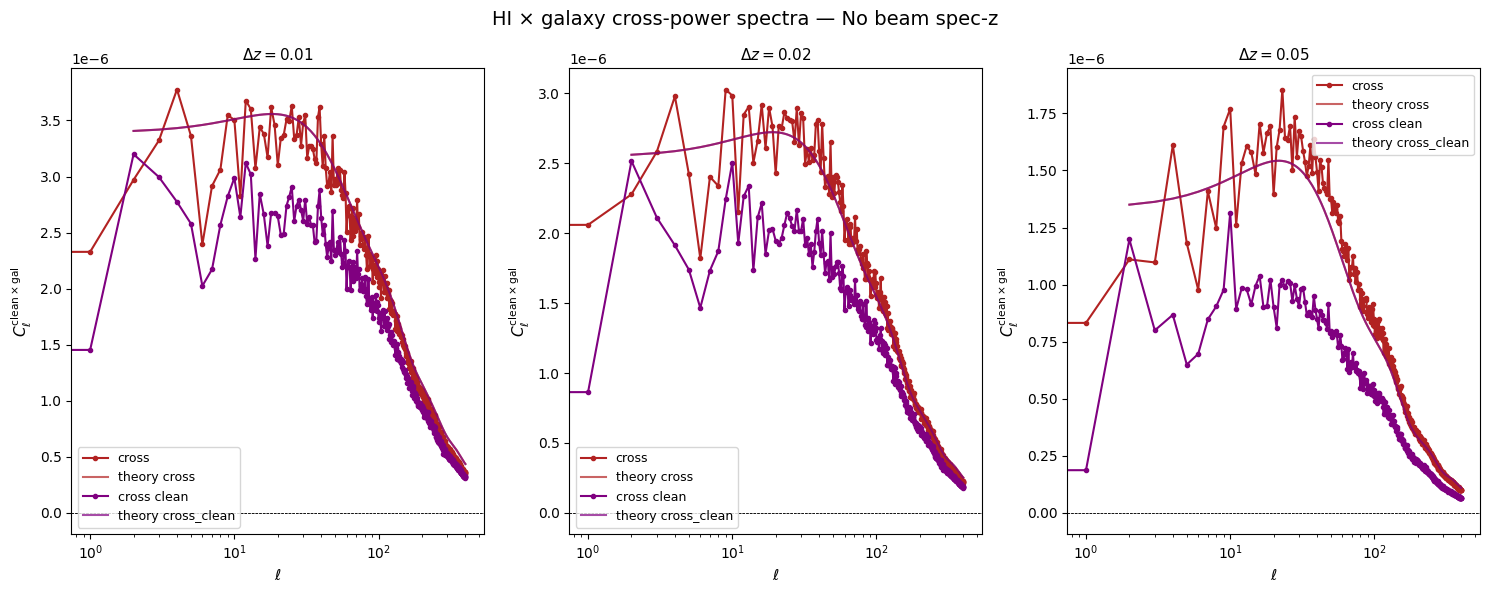

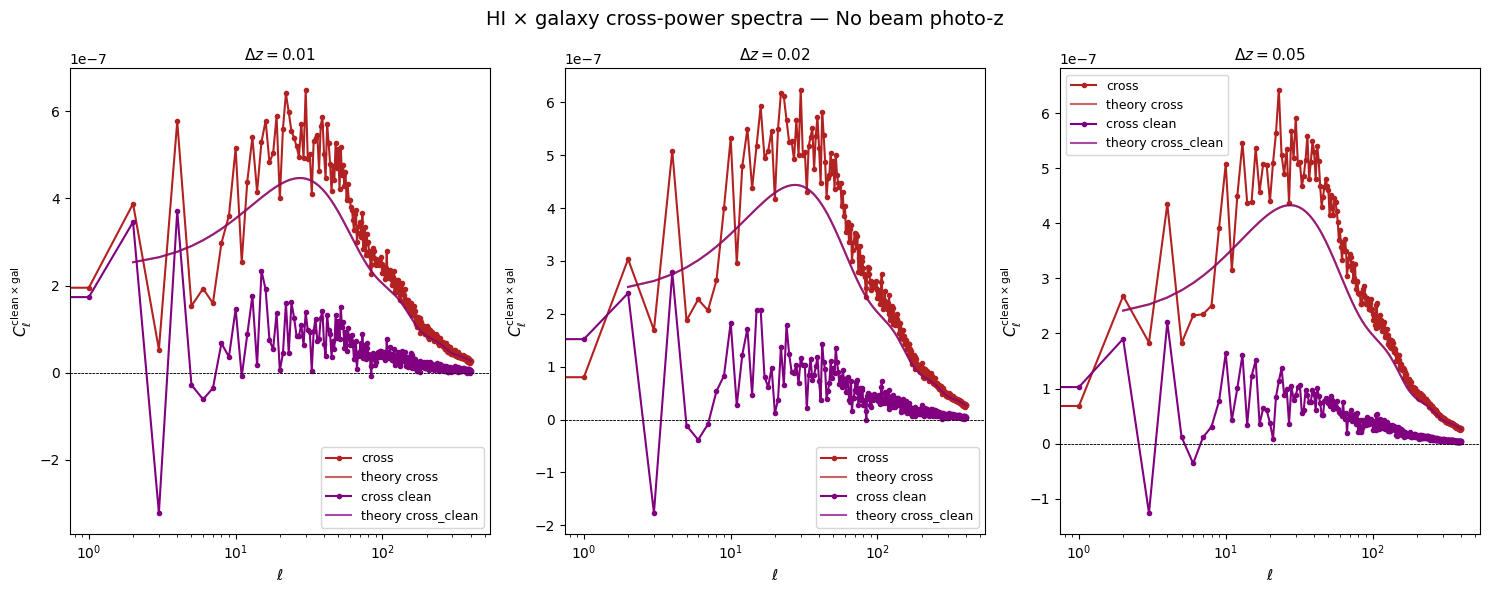

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import camb
from miscelanious import cosmology, get_pk, dndz_des_alonso, _gen_random_catalogue_theta, W_err
from camb import model
from camb.sources import SplinedSourceWindow



csm = cosmology(0.31, 0.05, 1-0.31, 0.6774, -1.0, 0.967, np.nan, 2.142e-9)
csm, kh, pkh, f = get_pk(csm, 0.0)
lmax = 400
zs_theory = np.arange(0.1, 3.0, 0.0005)
bias_theory = np.ones_like(zs_theory)
thetas = np.linspace(0.1, 5, 100)

def make_camb(csm, lmax, zs, Ws, bias, cross = False):
    pars = camb.CAMBparams()
    pars.set_cosmology(H0=csm['h']*100, ombh2=csm['omega_B']*csm['h']**2, omch2=(csm['omega_M']-csm['omega_B'])*csm['h']**2)
    pars.InitPower.set_params(As=csm['As'], ns=csm['ns'])
    pars.set_for_lmax(lmax, lens_potential_accuracy=1)
    pars.NonLinear = model.NonLinear_none
    
    pars.Want_CMB, pars.Want_CMB_lensing, pars.DoLensing                                                    = False, False, False
    pars.SourceTerms.counts_velocity, pars.SourceTerms.counts_radial, pars.SourceTerms.counts_timedelay     = False, False, False
    pars.SourceTerms.counts_ISW, pars.SourceTerms.counts_potential, pars.SourceTerms.counts_evolve          = False, False, False
    pars.SourceTerms.line_phot_dipole, pars.SourceTerms.line_phot_quadrupole, pars.SourceTerms.line_basic   = False, False, False
    pars.SourceTerms.line_distortions, pars.SourceTerms.line_extra, pars.SourceTerms.line_reionization      = False, False, False
    pars.SourceTerms.use_21cm_mK                                                                            = False      
    pars.SourceTerms.counts_density, pars.SourceTerms.counts_redshift, pars.SourceTerms.counts_lensing      = True, False, False

    if cross:
        pars.SourceWindows = [SplinedSourceWindow(z = zs[0], W = Ws[0], bias_z = bias[0]),
                              SplinedSourceWindow(z = zs[1], W = Ws[1], bias_z = bias[1])]
        map_ = 'W1xW2'
    else:
        pars.SourceWindows = [SplinedSourceWindow(z = zs, W = Ws, bias_z = bias)]
        map_ = 'W1xW1'
    results = camb.get_results(pars)
    cls = results.get_source_cls_dict(raw_cl=True)[map_][2 : lmax + 1]
    ls = np.arange(2, lmax+1)

    return ls, cls


seeds     = range(1010, 1110, 10)
prefixes  = ['sim_', 'beamed_']
photos    = ['spec_', 'photo_']
bins      = ['0_01', '0_02', '0_05']
cl_cols   = ['cl_h1', 'cl_clean', 'cl_gal', 'cl_cross', 'cl_cross_clean']

results = {}

for pref, photo, b in product(prefixes, photos, bins):
    fname = f"{pref}{photo}cls_bin_{b}.csv"
    key   = (pref, photo, b)

    seed_data = {col: [] for col in cl_cols}
    ell_ref   = None

    for seed in seeds:
        path = f"./variance/colore_run_seed_{seed}/{fname}"
        df   = pd.read_csv(path, index_col=0)

        if ell_ref is None:
            ell_ref = np.array(range(len(df['cl_h1'].values)))

        for col in cl_cols:
            seed_data[col].append(df[col].values)

    # stack → shape (10, n_ell); then mean and cov
    entry = {'ell': ell_ref}
    for col in cl_cols:
        mat             = np.array(seed_data[col])          # (10, n_ell)
        entry[f'mean_{col}'] = mat.mean(axis=0)             # (n_ell,)
        entry[f'cov_{col}']  = np.cov(mat.T)               # (n_ell, n_ell)
        entry[f'std_{col}']  = np.sqrt(np.diag(entry[f'cov_{col}']))

    results[key] = entry

bin_labels = {'0_01': r'$\Delta z = 0.01$',
              '0_02': r'$\Delta z = 0.02$',
              '0_05': r'$\Delta z = 0.05$'}

colors_auto  = {'sim_spec_':   ('steelblue',  'darkorange'),
                'sim_photo_':  ('steelblue',  'darkorange'),
                'beamed_spec_':('steelblue',  'darkorange'),
                'beamed_photo_':('steelblue', 'darkorange')}

linestyles = {'sim_spec_': '-', 'sim_photo_': '--',
              'beamed_spec_': '-.', 'beamed_photo_': ':'}

def combo_key(pref, photo):
    return pref + photo

# for pref in prefixes:
pref = 'sim_'
for photo in photos:
    ck  = combo_key(pref, photo)
    ls  = linestyles[ck]
    c1, c2 = 'firebrick', 'purple'
    title_tag = f"{'Beamed' if pref=='beamed_' else 'No beam'} {'photo-z' if photo=='photo_' else 'spec-z'}"

    fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=False)
    fig.suptitle(f"HI × galaxy cross-power spectra — {title_tag}", fontsize=14)

    for col_idx, b in enumerate(bins):
        entry = results[(pref, photo, b)]
        ell   = entry['ell']

        if b=='0_01':
            lower_z = 0.73
            upper_z = 0.72
        elif b=='0_02':
            lower_z = 0.715
            upper_z = 0.735
        elif b=='0_05':
            lower_z = 0.7
            upper_z = 0.75
            
        if photo=='photo_':
            l_th, cl_th = make_camb(csm, lmax, [zs_theory, zs_theory], 
                                    [W_err(zs_theory, (lower_z+upper_z)/2, abs(lower_z-upper_z)/2, 0.001), 
                                     W_err(zs_theory, (lower_z+upper_z)/2, abs(lower_z-upper_z)/2, 0.05 * (1 + zs_theory)) * dndz_des_alonso(zs_theory)], 
                                     [bias_theory, bias_theory], cross = True)
        elif photo=='spec_':
            l_th, cl_th = make_camb(csm, lmax, [zs_theory, zs_theory], 
                                    [W_err(zs_theory, (lower_z+upper_z)/2, abs(lower_z-upper_z)/2, 0.001), 
                                     W_err(zs_theory, (lower_z+upper_z)/2, abs(lower_z-upper_z)/2, 0.001) * dndz_des_alonso(zs_theory)], 
                                     [bias_theory, bias_theory], cross = True)
        

        for row_idx, (col, color, ylabel) in enumerate([
            ('cl_cross',       c1, r'$C_\ell^{\rm HI\times gal}$'),
            ('cl_cross_clean', c2, r'$C_\ell^{\rm clean\times gal}$'),
        ]):
            ax  = axes[col_idx]
            y   = entry[f'mean_{col}'] #* ell
            err = entry[f'std_{col}'] #* ell

            ax.plot(ell, y, color=color, marker='.', ls='-', label=col.replace('cl_', '').replace('_', ' '))
            #ax.fill_between(ell, y - err, y + err, color=color, alpha=0.25)
            ax.plot(l_th, cl_th * 0.05, color=color, ls='-', alpha=0.7, label=f'theory {col.replace("cl_", "")}')
            ax.axhline(0, color='k', lw=0.5, ls='--')
            ax.set_xscale('log')
            ax.set_xlabel(r'$\ell$', fontsize=11)
            ax.set_ylabel(ylabel, fontsize=11)
            ax.set_title(bin_labels[b], fontsize=11)
            ax.legend(fontsize=9)

    plt.tight_layout()
    plt.show()


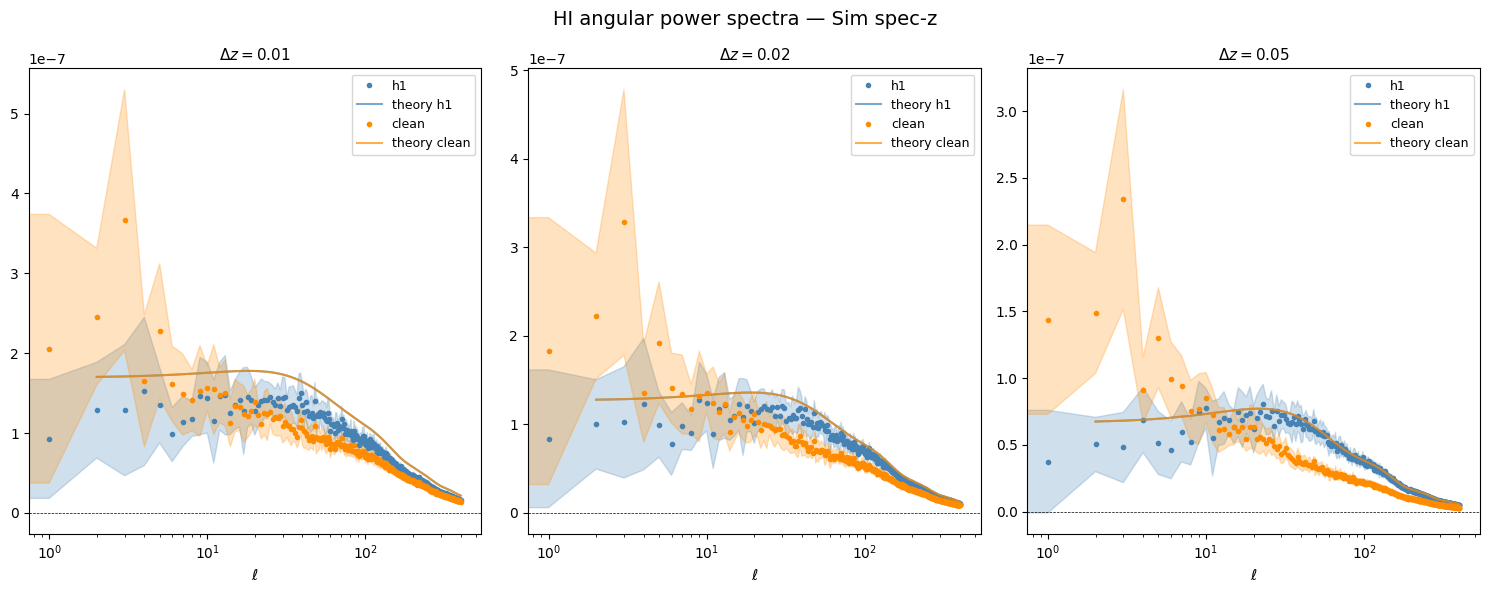

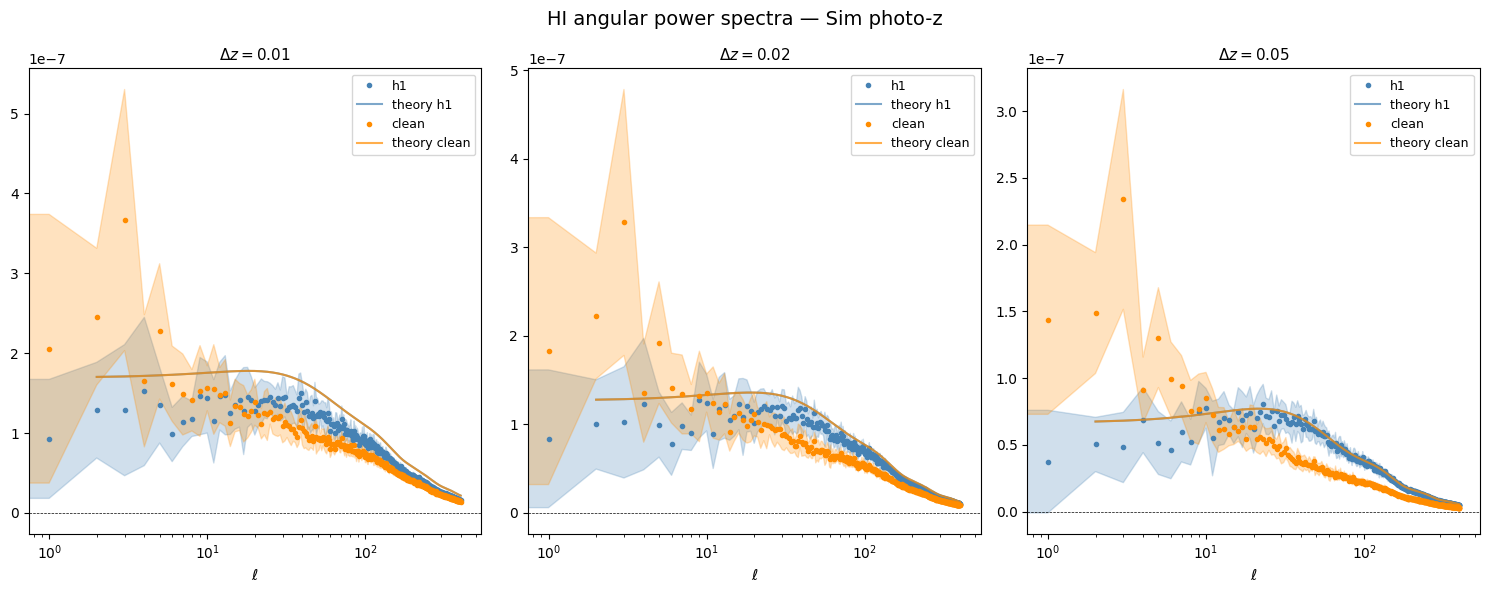

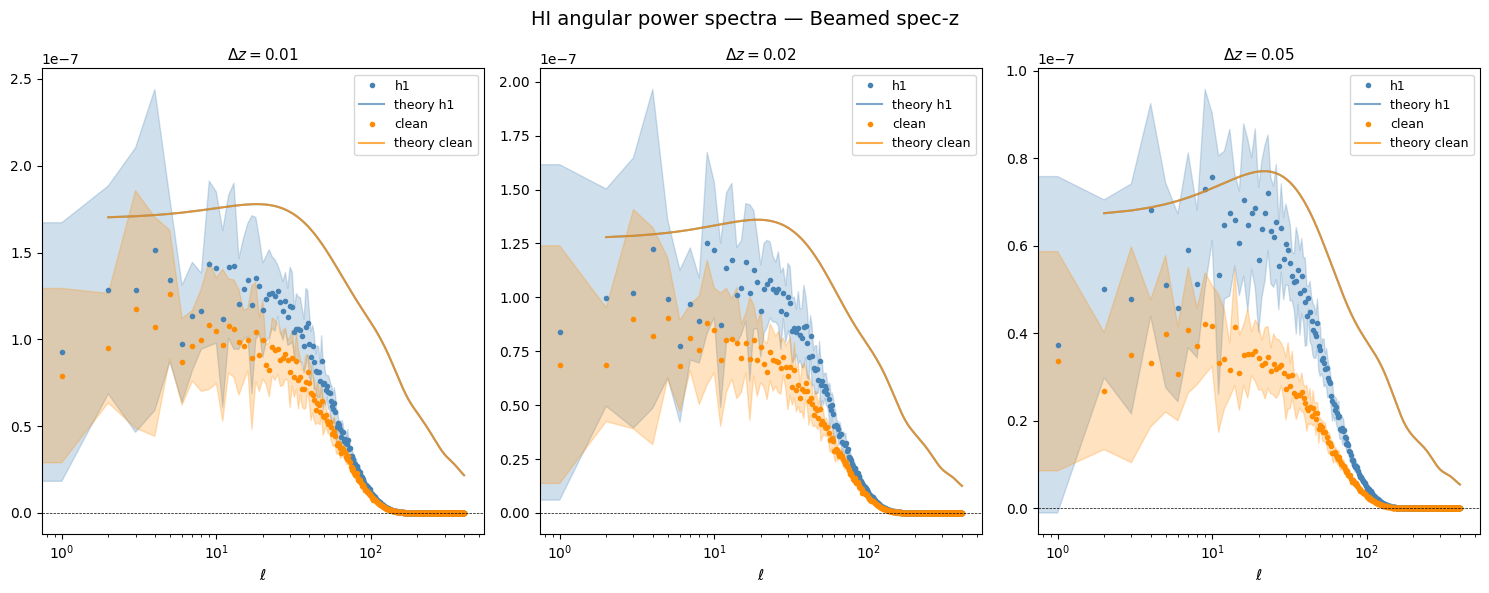

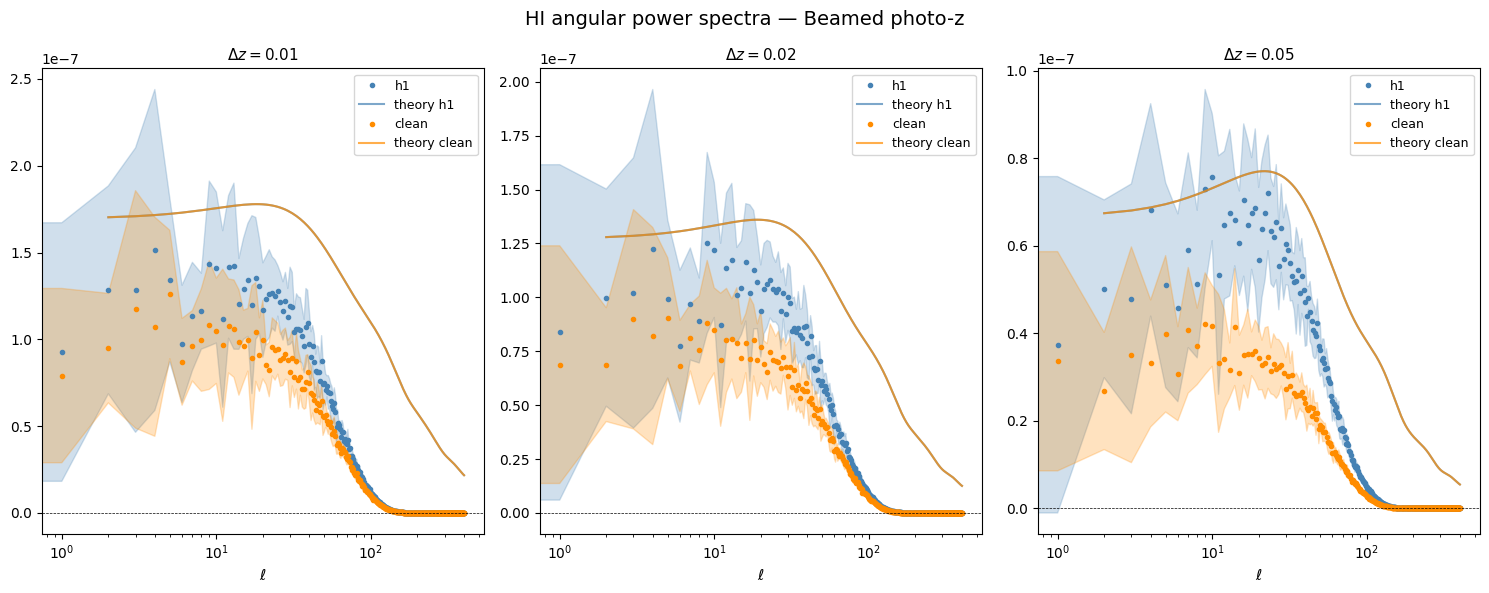

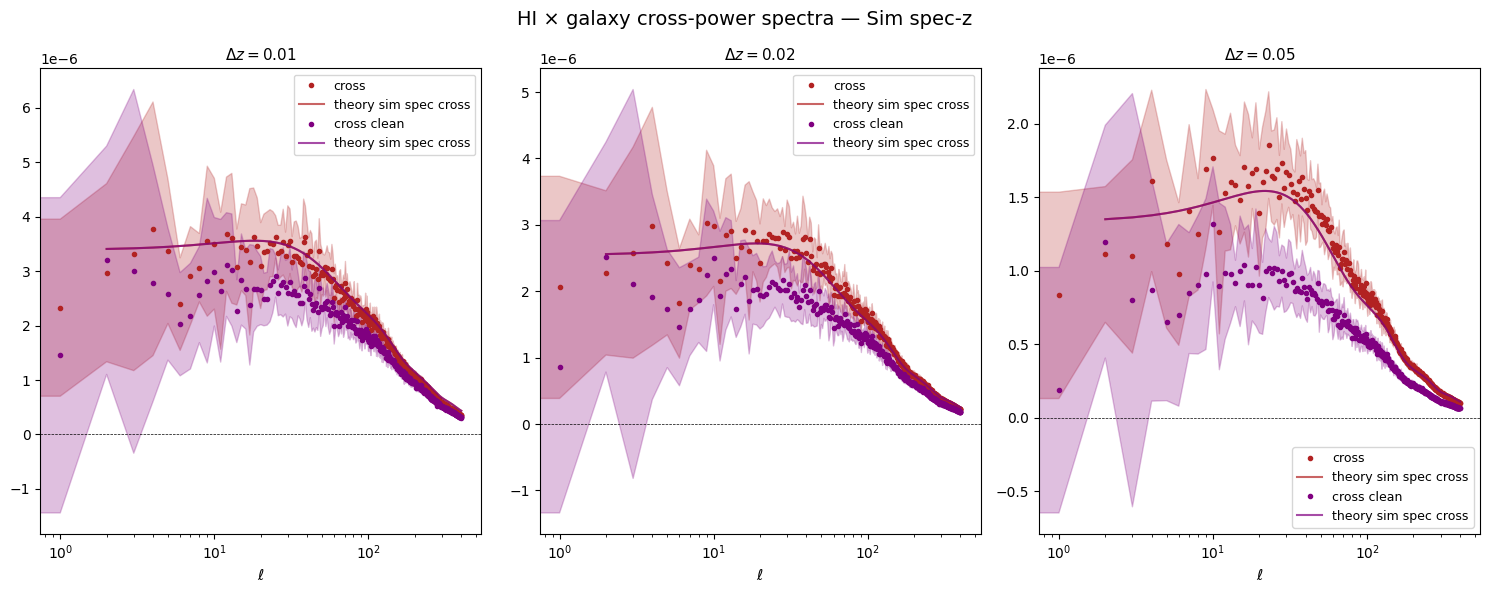

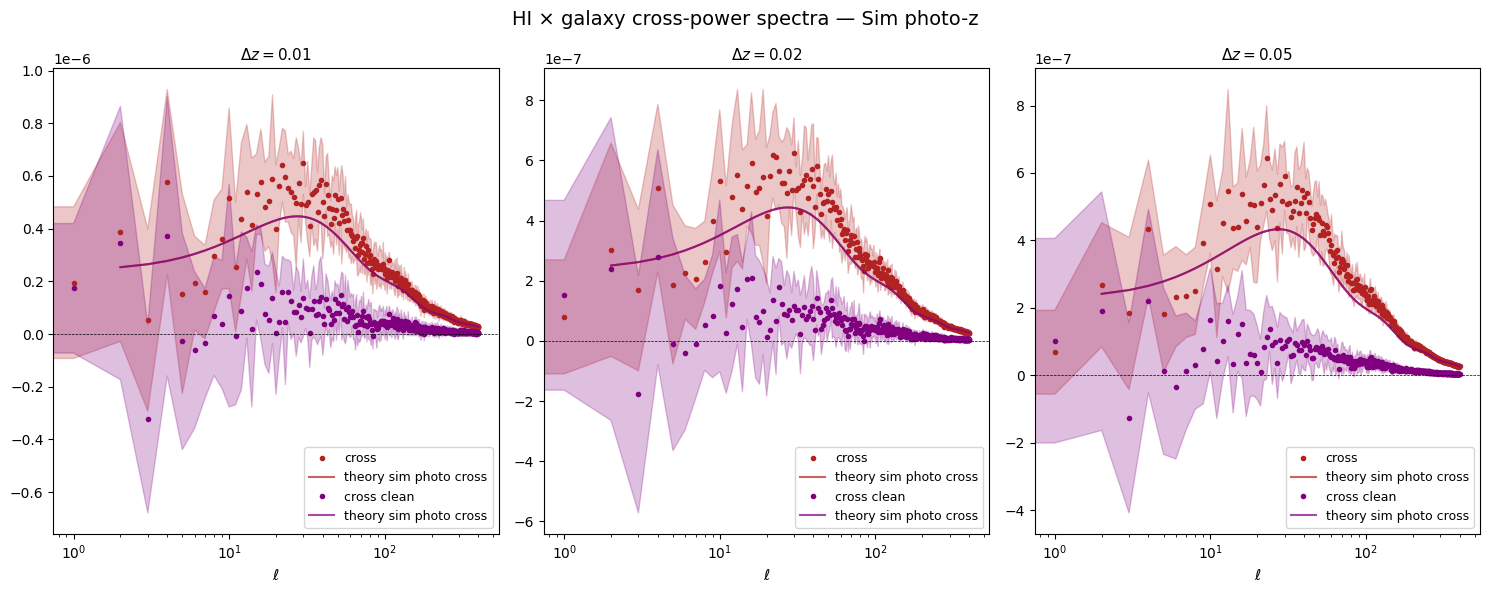

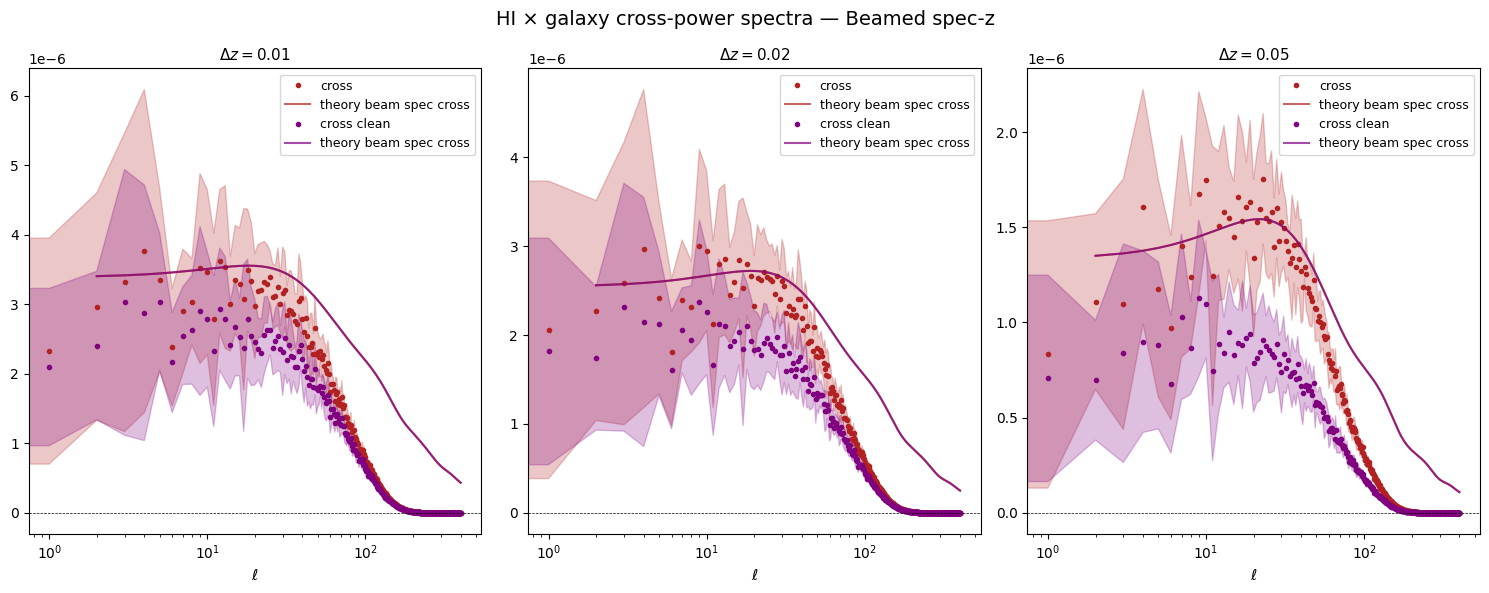

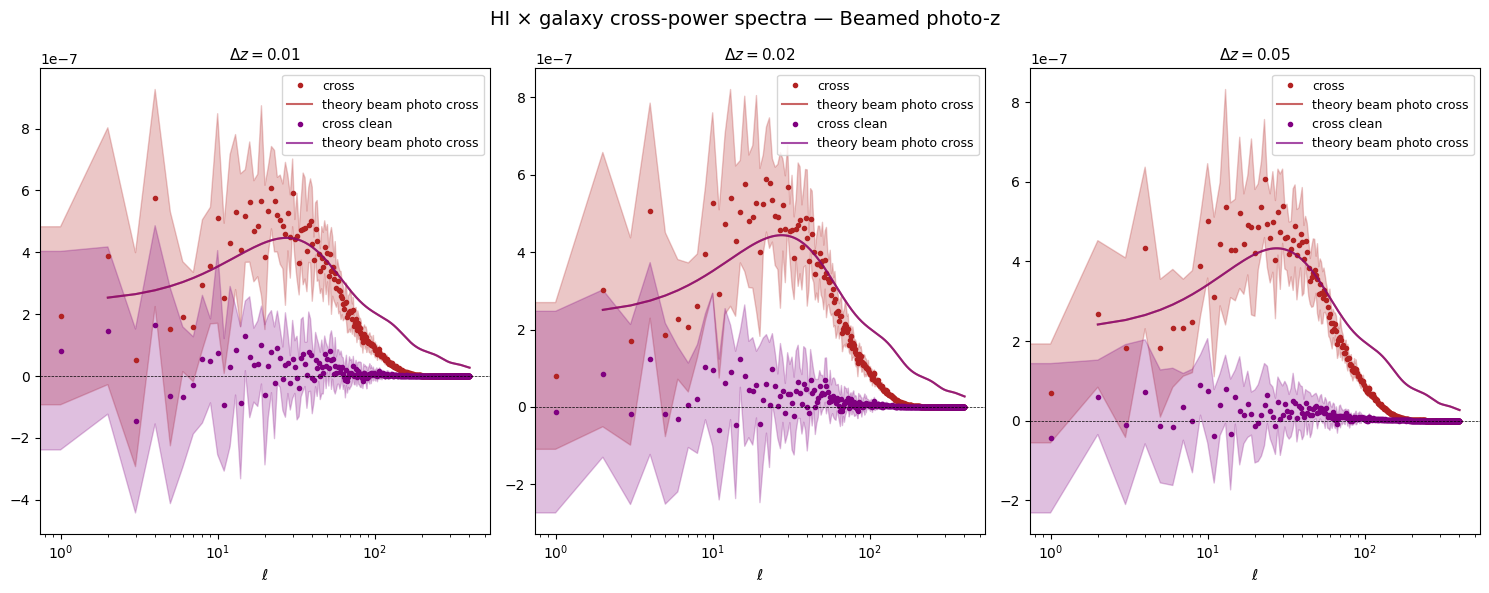

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product

seeds     = range(1010, 1110, 10)
prefixes  = ['sim_', 'beamed_']
photos    = ['spec_', 'photo_']
bins      = ['0_01', '0_02', '0_05']
cl_cols   = ['cl_h1', 'cl_clean', 'cl_gal', 'cl_cross', 'cl_cross_clean']

results = {}

for pref, photo, b in product(prefixes, photos, bins):
    fname = f"{pref}{photo}cls_bin_{b}.csv"
    key   = (pref, photo, b)

    seed_data = {col: [] for col in cl_cols}
    ell_ref   = None

    for seed in seeds:
        path = f"./variance/colore_run_seed_{seed}/{fname}"
        df   = pd.read_csv(path, index_col=0)

        if ell_ref is None:
            ell_ref = np.array(range(len(df['cl_h1'].values)))

        for col in cl_cols:
            seed_data[col].append(df[col].values)

    entry = {'ell': ell_ref}
    for col in cl_cols:
        mat                  = np.array(seed_data[col])
        entry[f'mean_{col}'] = mat.mean(axis=0)
        entry[f'cov_{col}']  = np.cov(mat.T)
        entry[f'std_{col}']  = np.sqrt(np.diag(entry[f'cov_{col}']))

    results[key] = entry

# ── Load theory cls ───────────────────────────────────────────────────────────
theory = {}
for b in bins:
    df = pd.read_csv(f"./variance/theory_cls_{b}.csv", index_col=0)
    theory[b] = {
        'ls':                    df['ls_theory_sim_hi'].values[:400],
        'sim_hi':                df['cls_theory_sim_hi'].values[:400],
        'beam_hi':               df['cls_theory_beam_hi'].values[:400],
        'spec_gal':              df['cls_theory_spec_gal'].values[:400],
        'photo_gal':             df['cls_theory_photo_gal'].values[:400],
        'sim_spec_cross':        df['cls_theory_sim_spec_cross'].values[:400],
        'sim_photo_cross':       df['cls_theory_sim_photo_cross'].values[:400],
        'beam_spec_cross':       df['cls_theory_beam_spec_cross'].values[:400],
        'beam_photo_cross':      df['cls_theory_beam_photo_cross'].values[:400],
    }

bin_labels = {'0_01': r'$\Delta z = 0.01$',
              '0_02': r'$\Delta z = 0.02$',
              '0_05': r'$\Delta z = 0.05$'}

linestyles = {'sim_spec_': '-', 'sim_photo_': '--',
              'beamed_spec_': '-.', 'beamed_photo_': ':'}

def combo_key(pref, photo):
    return pref + photo

# ── HI auto plots ─────────────────────────────────────────────────────────────
for pref in prefixes:
    for photo in photos:
        ck        = combo_key(pref, photo)
        ls        = linestyles[ck]
        c1, c2    = 'steelblue', 'darkorange'
        title_tag = f"{'Beamed' if pref=='beamed_' else 'Sim'} {'photo-z' if photo=='photo_' else 'spec-z'}"

        # select correct theory hi key based on beam
        theory_hi_key = 'beam_hi' if pref == 'beamed_' else 'sim_hi'

        fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=False)
        fig.suptitle(f"HI angular power spectra — {title_tag}", fontsize=14)

        for col_idx, b in enumerate(bins):
            entry   = results[(pref, photo, b)]
            ell     = entry['ell']
            ax      = axes[col_idx]
            th      = theory[b]

            for col, color, ylabel, th_key in [
                ('cl_h1',    c1, r'$C_\ell^{\rm HI}$',    theory_hi_key),
                ('cl_clean', c2, r'$C_\ell^{\rm clean}$',  theory_hi_key),
            ]:
                y   = entry[f'mean_{col}']
                err = entry[f'std_{col}']

                ax.plot(ell, y, color=color, marker='.', ls='',
                        label=col.replace('cl_', ''))
                ax.fill_between(ell, y - err, y + err, color=color, alpha=0.25)
                ax.plot(th['ls'], th[th_key] * 0.05**2, color=color, ls='-', lw=1.5,
                        alpha=0.7, label=f'theory {col.replace("cl_", "")}')

            ax.axhline(0, color='k', lw=0.5, ls='--')
            ax.set_xscale('log')
            ax.set_xlabel(r'$\ell$', fontsize=11)
            ax.set_title(bin_labels[b], fontsize=11)
            ax.legend(fontsize=9)

        plt.tight_layout()
        plt.show()

# ── Cross-correlation plots ───────────────────────────────────────────────────
for pref in prefixes:
    for photo in photos:
        ck        = combo_key(pref, photo)
        ls        = linestyles[ck]
        c1, c2    = 'firebrick', 'purple'
        title_tag = f"{'Beamed' if pref=='beamed_' else 'Sim'} {'photo-z' if photo=='photo_' else 'spec-z'}"

        # select correct theory cross key based on beam and photo
        beam_tag  = 'beam' if pref == 'beamed_' else 'sim'
        photo_tag = 'photo' if photo == 'photo_' else 'spec'
        theory_cross_key = f'{beam_tag}_{photo_tag}_cross'

        fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=False)
        fig.suptitle(f"HI × galaxy cross-power spectra — {title_tag}", fontsize=14)

        for col_idx, b in enumerate(bins):
            entry = results[(pref, photo, b)]
            ell   = entry['ell']
            ax    = axes[col_idx]
            th    = theory[b]

            for col, color, ylabel in [
                ('cl_cross',       c1, r'$C_\ell^{\rm HI\times gal}$'),
                ('cl_cross_clean', c2, r'$C_\ell^{\rm clean\times gal}$'),
            ]:
                y   = entry[f'mean_{col}']
                err = entry[f'std_{col}']

                ax.plot(ell, y, color=color, marker='.', ls='',
                        label=col.replace('cl_', '').replace('_', ' '))
                ax.fill_between(ell, y - err, y + err, color=color, alpha=0.25)
                ax.plot(th['ls'], th[theory_cross_key] * 0.05, color=color, ls='-', lw=1.5,
                        alpha=0.7, label=f'theory {theory_cross_key.replace("_", " ")}')

            ax.axhline(0, color='k', lw=0.5, ls='--')
            ax.set_xscale('log')
            ax.set_xlabel(r'$\ell$', fontsize=11)
            ax.set_title(bin_labels[b], fontsize=11)
            ax.legend(fontsize=9)

        plt.tight_layout()
        plt.show()


# for pref in prefixes:
#     for photo in photos:
#         ck  = combo_key(pref, photo)
#         ls  = linestyles[ck]
#         c1, c2 = 'steelblue', 'darkorange'
#         title_tag = f"{'Beamed' if pref=='beamed_' else 'Sim'} {'photo-z' if photo=='photo_' else 'spec-z'}"

#         fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharex=False)
#         fig.suptitle(f"HI angular power spectra — {title_tag}", fontsize=14)

#         for col_idx, b in enumerate(bins):
#             entry = results[(pref, photo, b)]
#             ell   = entry['ell']

#             for row_idx, (col, color, ylabel) in enumerate([
#                 ('cl_h1',    c1, r'$C_\ell^{\rm HI}$'),
#                 ('cl_clean', c2, r'$C_\ell^{\rm clean}$'),
#             ]):
#                 ax  = axes[col_idx]
#                 y   = entry[f'mean_{col}'] #* ell
#                 err = entry[f'std_{col}'] #* ell

#                 ax.plot(ell, y, color=color, marker='.', ls='', label=col.replace('cl_', ''))
#                 ax.fill_between(ell, y - err, y + err, color=color, alpha=0.25)
#                 ax.axhline(0, color='k', lw=0.5, ls='--')
#                 ax.set_xscale('log')
#                 ax.set_xlabel(r'$\ell$', fontsize=11)
#                 ax.set_ylabel(ylabel, fontsize=11)
#                 ax.set_title(bin_labels[b], fontsize=11)
#                 ax.legend(fontsize=9)

#         plt.tight_layout()
#         plt.show()